# ARM KAZR Cloud Persistence Project: V2 Results & Guided Tour

**Alec Blevins - November 6th, 2026**

## Purpose
Welcome. Post running `src.modeling.py`, this notebook walks through each pipeline step, then shows the results. It reads only the small files in `V2_results/` (available in github), so it runs without the raw data. 

### **Question:** Given that the sky is cloudy right now at the ARM SGP site, will it still be cloudy for the *whole* next 20 minutes? 

**Data:** One year (2024) of KAZR ARSCL radar-derived cloud products at SGP, one file per day. The cloud-layer base heights tell us, every 4 seconds, whether any cloud is overhead. 

**Approach:** Turn the raw files into a table with one row per cloudy 20-second moment, describe each moment with features computed from the past only, label it by what happens next, then train and evaluate models on a strictly later time period than they were trained on. 

## 0. Library Imports & V2 Results Load

In [7]:
#Library Import
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import precision_recall_curve

#Path Definition
ROOT = Path("..")
RES = ROOT / "V2_results"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)

#Data Import
R = json.loads((RES / "results.json").read_text()) #JSON results
roll = pd.read_csv(RES / "rolling_origin.csv") #Rolling origin results
pred = pd.read_parquet(RES / "predictions.parquet") #Predictions

#Plotting Configuration
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

print(pred.shape); pred.head()

(198692, 6)


,fold,y,run_length_min,lead_min,p_hgb,p_logit
time,,,,,,
2024-09-01 00:00:40,val,0,0.333333,35.333333,0.775199,0.752026
2024-09-01 00:01:00,val,0,0.666667,35.000000,0.793411,0.797619
2024-09-01 00:01:20,val,0,1.000000,34.666667,0.739811,0.711864
2024-09-01 00:01:40,val,0,1.333333,34.333333,0.874810,0.908270
2024-09-01 00:02:00,val,0,1.666667,34.000000,0.879698,0.880540


## Step 1. Cloud State 
Each KAZR file lists the base height of up to several cloud layers every 4 seconds. 

- **CLOUDY:** at least one layer has a valid base height. 
- **CLEAR:** every layer slot reports "no cloud" (-1). 
- **UNKNOWN:** anything else, such as missing data or instrument downtime. 

Five 4 second samples are combined into a **20 second bin**. Bins with an unknown state are never filled in, because guessing would invent persistence or dissolution. The year has 1,581,120 bins; 764,599 are cloudy, and those are the rows we model. 

## Step 2. The Target
For every cloudy moment *t*, we look at the next 20 minutes (60 bins of 20 seconds): 

| Window (t, t+20 min] | Label |
|---|---|
| every bin cloudy | **persisted** |
| at least one bin known clear | **dissolved** (the positive class) |
| otherwise (unknown gaps) | dropped |

We predict *dissolution* because it is the rarer, more useful event, and it makes precision and recall easy to read. 20 minutes balances two things: 
- a 1 minute horizon is 96.6% persistent, so there is little left to predict, 
- and longer ones mostly measure whether *any* cloud ever leaves. 

Of 764,599 cloudy moments, 764,267 have a valid label and 158,795 (20.8%) dissolve. We use numbers according to discussion in `07_annual_target_sketch.ipynb`. 


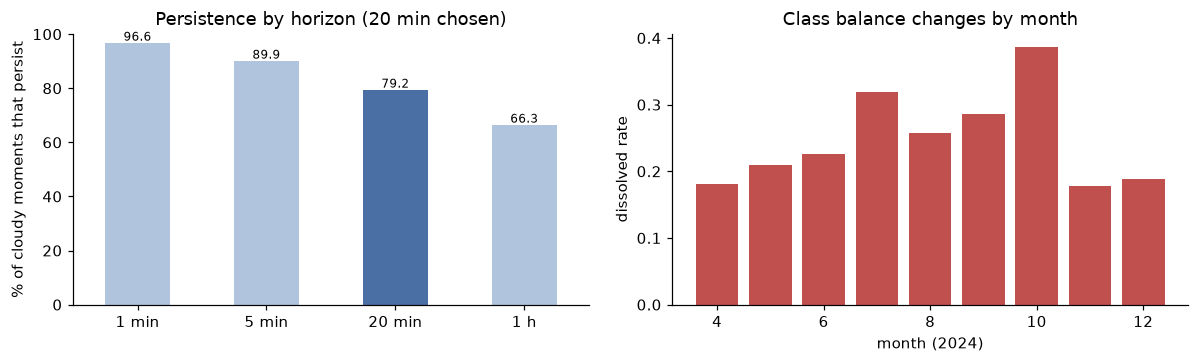

In [8]:
# Persistence target, p_persisted by horizon (notebook 07)
hz = pd.Series({"1 min": 96.57, "5 min": 89.92, "20 min": 79.22, "1 h": 66.26})

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
hz.plot.bar(ax=ax[0], color=["#b0c4de", "#b0c4de", "#4a6fa5", "#b0c4de"], rot=0)
ax[0].set_ylabel("% of cloudy moments that persist")
ax[0].set_title("Persistence by horizon (20 min chosen)")
ax[0].set_ylim(0, 100)
for i, v in enumerate(hz):
    ax[0].text(i, v + 1, f"{v:.1f}", ha="center", fontsize=8)

ax[1].bar(roll.month, roll.rate, color="#c0504d")
ax[1].set_xlabel("month (2024)"); ax[1].set_ylabel("dissolved rate")
ax[1].set_title("Class balance changes by month")
fig.tight_layout(); fig.savefig(FIG / "12_target.png", bbox_inches="tight"); plt.show()

## Step 3: Features (23, past-only)
Every feature at time *t* uses only data up to the end of *t*'s bin. A test (notebook 08/11) removes all later data and checks the features are unchanged. 

| Group | Examples | Feature Count |
|---|---|---|
| Cloud fraction and age | cloud fraction, run length (minutes cloudy so far) | 2 |
| Short-term history | mean, min, change, and flips of cloud fraction over 1, 5, 20 min | 12 |
| Vertical structure | layer count, lowest base, highest top, vertical span, 5-min changes | 6 |
| Context | hour of day (sin/cos), radar availability | 3 |

## Step 4: Chronological Splits
Random splits would leak: neighbouring 20 second rows are nearly identical. Instead, the model is trained on the past and judged on nthe future, with a 20 minute **embargo** before each boundary so no training target looks into the next fold

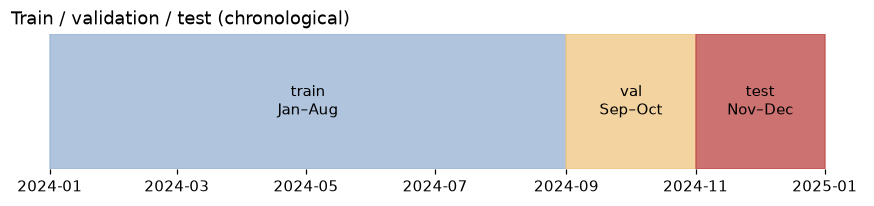

           n  dissolved_rate
fold                        
test  121645           0.183
val    77047           0.327


In [9]:
#Plot train / validation / test splits - document splits over time
fig, ax = plt.subplots(figsize=(10, 1.6))
spans = [("train\nJan–Aug", "2024-01-01", "2024-09-01", "#9db7d5"),
         ("val\nSep–Oct", "2024-09-01", "2024-11-01", "#f0c987"),
         ("test\nNov–Dec", "2024-11-01", "2025-01-01", "#c0504d")]
for lab, a, b, c in spans:
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    ax.axvspan(a, b, color=c, alpha=.8)
    ax.text(a + (b - a) / 2, .5, lab, ha="center", va="center")
ax.set_yticks([]); ax.set_title("Train / validation / test (chronological)", loc="left")
for s in ["left", "bottom"]: ax.spines[s].set_visible(False)
fig.savefig(FIG / "12_splits.png", bbox_inches="tight"); plt.show()
print(pred.groupby("fold").y.agg(n="size", dissolved_rate="mean").round(3))

## Step 5: Models & Metrics
- **-run_length**: a one-feature baseline (older clouds persist)
- **Logistic Regression**: a linear model on all 23 features
- **Histogram Gradient Boosting (HGB)**: the main model, which captures nonlinear structure. 

**PR-AUC** is the primary metric: how well the model ranks dissolving moments above persisting ones while staying precise (precision vs. recall). Its no-skill level equals the dissolved rate, so a score of 0.65 menas different things at 18% and 33% base rates. 

**ROC-AUC** is stable across periods (true positive rate vs. false positive rate). 

A **threshold** (0.315, chosen on validation to maximise F1) converts a probability into an alarm; it is frozen before the test period is scored. 

The **95% interval** resamples whole test days. 

### Model Comparison

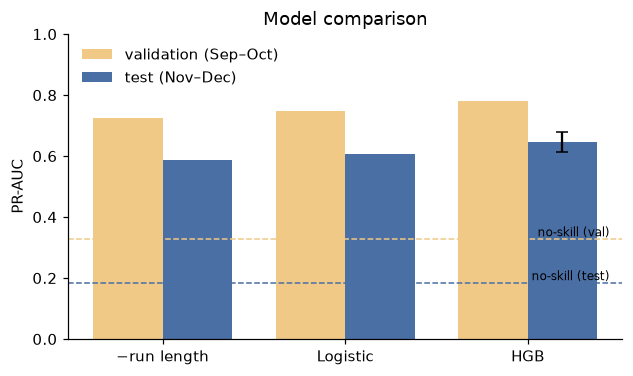

,val,test
model,,
−run length,0.725,0.588
Logistic,0.747,0.606
HGB,0.781,0.646


In [10]:
names = {"-run_length": "−run length", "logit": "Logistic", "hgb": "HGB"} # Mapping of model keys to display names
t, v = R["test"], R["val"] # Extract test and validation results from R
rows = [(n, v[k]["pr_auc"], t[k]["pr_auc"]) for k, n in names.items()] # Create rows for comparison DataFrame with model name, validation PR-AUC, and test PR-AUC
cmp_ = pd.DataFrame(rows, columns=["model", "val", "test"]).set_index("model") # Create comparison DataFrame with model names as index

#Plot model comparison with validation and test PR-AUC
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(cmp_)); w = .38
ax.bar(x - w/2, cmp_.val, w, label="validation (Sep–Oct)", color="#f0c987")
ax.bar(x + w/2, cmp_.test, w, label="test (Nov–Dec)", color="#4a6fa5")
lo, hi = t["hgb"]["pr_auc_ci95"]; hp = t["hgb"]["pr_auc"]
ax.errorbar(2 + w/2, hp, yerr=[[hp - lo], [hi - hp]], color="k", capsize=4)
ax.axhline(v["hgb"]["rate"], color="#f0c987", ls="--", lw=1)
ax.axhline(t["no_skill"]["pr_auc"], color="#4a6fa5", ls="--", lw=1)
ax.text(2.45, t["no_skill"]["pr_auc"] + .01, "no-skill (test)", ha="right", fontsize=8)
ax.text(2.45, v["hgb"]["rate"] + .01, "no-skill (val)", ha="right", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(cmp_.index)
ax.set_ylabel("PR-AUC"); ax.set_ylim(0, 1); ax.legend(frameon=False, loc="upper left")
ax.set_title("Model comparison")
fig.savefig(FIG / "12_model_comparison.png", bbox_inches="tight"); plt.show()
cmp_.round(3)

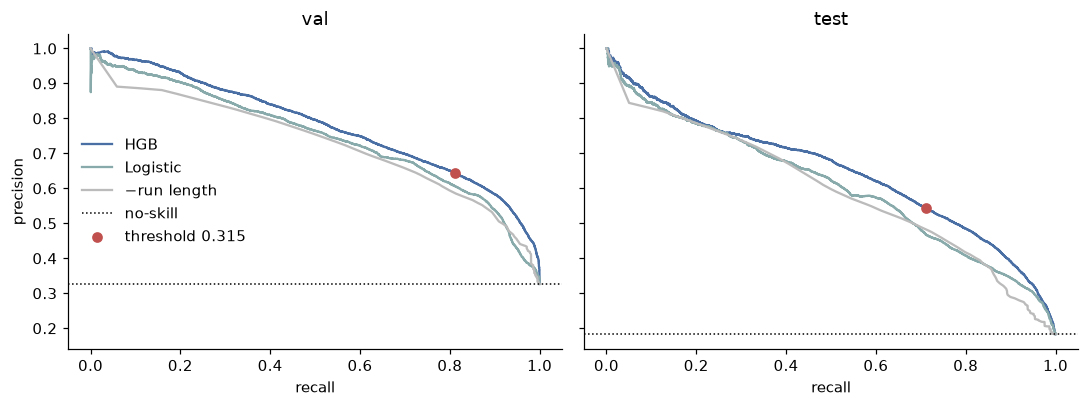

In [11]:
#Plot precision-recall curves for validation and test sets
# This section visualizes the precision-recall performance of different models on the validation and test datasets.
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, f in zip(axs, ["val", "test"]):
    d = pred[pred.fold == f]
    for col, lab, c in [("p_hgb", "HGB", "#4a6fa5"), ("p_logit", "Logistic", "#8aa")]:
        p, r, _ = precision_recall_curve(d.y, d[col])
        ax.plot(r, p, label=lab, color=c)
    p, r, _ = precision_recall_curve(d.y, -d.run_length_min)
    ax.plot(r, p, label="−run length", color="#bbb")
    ax.axhline(d.y.mean(), color="k", ls=":", lw=1, label="no-skill")
    m = R[f]["hgb"]
    ax.scatter(m["recall"], m["precision"], color="#c0504d", zorder=5,
               label=f"threshold {m['thr']:.3f}")
    ax.set_title(f"{f}"); ax.set_xlabel("recall")
axs[0].set_ylabel("precision"); axs[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "12_pr_curves.png", bbox_inches="tight"); plt.show()